# 05 · Step 5: Who to message, and why uplift beats the obvious approach
**Question:** what does a marketer actually do with uplift scores, and is uplift really better than the usual "target likely buyers"?

| Part | What we do |
|---|---|
| A | **Head-to-head** on the locked 20% (same 40,008 customers as Step 4): uplift champion vs a normal likely-buyer model vs a "heavy shoppers" rule vs random. Who wins more *extra* buyers at the same budget? |
| B | **Simple rules:** a small "uplift tree" turns the data into 4–8 plain-English segments a marketer can use without a model. |
| C | **Personas:** group segments into High / Medium / Low uplift tiers, with size, real lift and a recommended action. |

**Pass mark:** at 20% targeted, uplift must win more extra buyers than the likely-buyer model; simple rules should keep most of the champion's gain.

## Cell 0 · Setup
Uses the same locked 20% as Step 4 (read from `holdout_scores.parquet`), so every comparison is on customers no model chose with.

In [1]:
import pandas as pd, numpy as np, duckdb, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from pathlib import Path
import lightgbm as lgb
from sklearn.tree import DecisionTreeRegressor
pd.set_option('display.width', 180); pd.set_option('display.max_colwidth', 120)

FEAT = Path('..') / 'data_x5' / 'features'
prof = duckdb.sql(f"SELECT * FROM '{(FEAT / 'customer_profiles.parquet').as_posix()}' WHERE in_experiment = 1").df()
prof = pd.concat([prof, pd.get_dummies(prof.gender, prefix='gender').astype(int)], axis=1)
X_COLS = [c for c in prof.columns if c not in {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}]
prof[X_COLS] = prof[X_COLS].astype('float32')
prof['treatment_flg'] = prof.treatment_flg.astype(int); prof['target'] = prof.target.astype(int)

hold_scores = duckdb.sql(f"SELECT client_id, champion FROM '{(FEAT / 'holdout_scores.parquet').as_posix()}'").df()
hold = prof.merge(hold_scores, on='client_id')                     # locked 20%, with champion scores
dev = prof[~prof.client_id.isin(hold_scores.client_id)]             # the 80% used for building
print(f'development {len(dev):,} | locked final exam {len(hold):,}')

development 160,031 | locked final exam 40,008


## Cell 1 · Part A: build the competitors
- **Likely-buyer model:** the standard approach. A LightGBM model learns *who buys when messaged* (trained on messaged customers in the 80%). It ranks by chance of buying, not by change caused.
- **Heavy-shoppers rule:** the marketer's gut feel. Rank by number of bills in the last 30 days.
- **Uplift champion:** Step 4's ensemble.
- **Random:** the baseline.

**Extra buyers per 10,000 customers** = real lift in the targeted group × size of the group. It is the number a CFO cares about.

In [2]:
dt = dev[dev.treatment_flg == 1]
likely = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8,
                            subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0, verbose=-1, random_state=42)
likely.fit(dt[X_COLS], dt.target)
rng = np.random.default_rng(0)
SCORES = {'Random': rng.random(len(hold)),
          'Heavy-shoppers rule': hold.n_bills_30d.values + rng.random(len(hold)) * 1e-3,
          'Likely-buyer model': likely.predict_proba(hold[X_COLS])[:, 1],
          'Uplift champion': hold.champion.values}
y, t = hold.target.values, hold.treatment_flg.values

def group_stats(sel):
    lift = y[sel & (t == 1)].mean() - y[sel & (t == 0)].mean()
    return dict(share=sel.mean(), buy_rate_if_messaged=y[sel & (t == 1)].mean(), real_lift_pts=lift * 100,
                extra_buyers_per_10k=lift * sel.mean() * 10000)
def top(score, k):
    return score >= np.quantile(score, 1 - k)

rows = []
for k in [0.1, 0.2, 0.3, 0.5]:
    for name, s in SCORES.items():
        rows.append({'target_top_%': int(k * 100), 'method': name, **group_stats(top(s, k))})
H = pd.DataFrame(rows)
display(H[H['target_top_%'] == 20].round(3))

,target_top_%,method,share,buy_rate_if_messaged,real_lift_pts,extra_buyers_per_10k
4,20,Random,0.2,0.648,3.836,76.714
5,20,Heavy-shoppers rule,0.2,0.905,0.969,19.377
6,20,Likely-buyer model,0.2,0.930,0.752,15.032
7,20,Uplift champion,0.2,0.518,8.868,177.359


## Cell 2 · The trap, in one chart
**Left:** buy rate of the customers each method picks (what a normal dashboard shows).
**Right:** extra buyers the message actually *creates* (what the business earns).
The likely-buyer model looks great on the left and poor on the right: it picks people who would buy anyway.

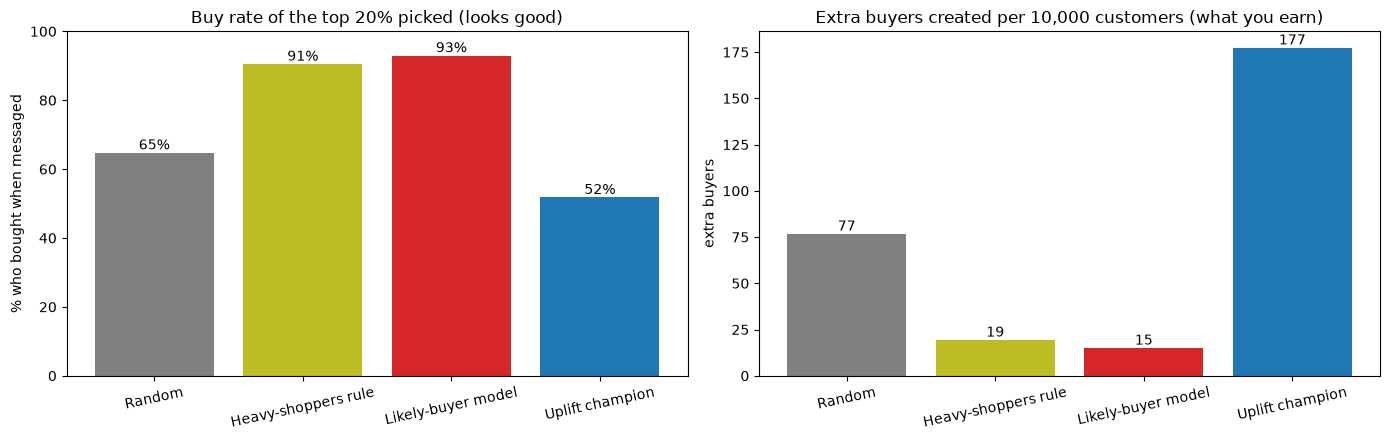

Uplift minus likely-buyer at 20%: +161 extra buyers per 10k (95% range +110 to +211)


In [3]:
h20 = H[H['target_top_%'] == 20].set_index('method').loc[list(SCORES)]
colors = ['grey', 'tab:olive', 'tab:red', 'tab:blue']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(h20.index, h20.buy_rate_if_messaged * 100, color=colors); ax[0].set_title('Buy rate of the top 20% picked (looks good)')
ax[0].set_ylabel('% who bought when messaged'); ax[0].set_ylim(0, 100)
ax[0].bar_label(ax[0].containers[0], fmt='%.0f%%')
ax[1].bar(h20.index, h20.extra_buyers_per_10k, color=colors); ax[1].set_title('Extra buyers created per 10,000 customers (what you earn)')
ax[1].set_ylabel('extra buyers'); ax[1].bar_label(ax[1].containers[0], fmt='%.0f')
for a in ax: a.tick_params(axis='x', rotation=12)
plt.tight_layout(); plt.show()

# 95% range for 'uplift minus likely-buyer' at 20%, by bootstrap
B = [rng.integers(0, len(y), len(y)) for _ in range(300)]
def extra_at(s, idx, k=0.2):
    yy, tt, ss = y[idx], t[idx], s[idx]; sel = ss >= np.quantile(ss, 1 - k)
    return (yy[sel & (tt == 1)].mean() - yy[sel & (tt == 0)].mean()) * sel.mean() * 10000
diff = [extra_at(SCORES['Uplift champion'], b) - extra_at(SCORES['Likely-buyer model'], b) for b in B]
print(f"Uplift minus likely-buyer at 20%: {np.mean(diff):+.0f} extra buyers per 10k (95% range {np.percentile(diff, 2.5):+.0f} to {np.percentile(diff, 97.5):+.0f})")

## Cell 3 · Extra buyers at every budget
How many extra buyers each method creates as you message more of the base.

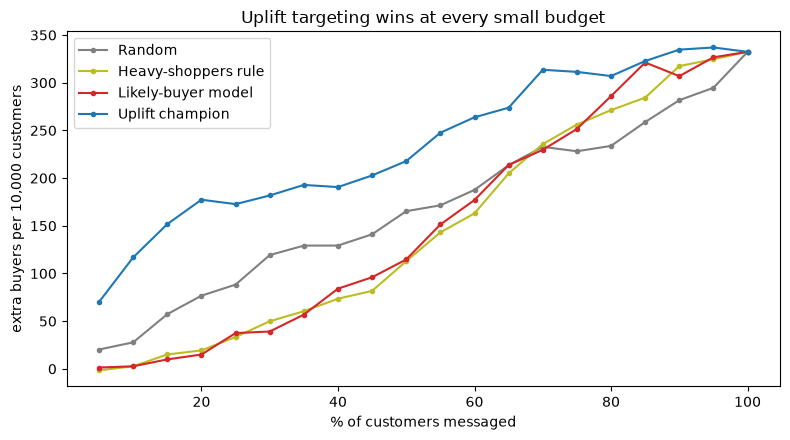

method,Random,Heavy-shoppers rule,Likely-buyer model,Uplift champion
target_top_%,,,,
10,28.0,3.0,3.0,117.0
20,77.0,19.0,15.0,177.0
30,119.0,50.0,39.0,182.0
50,165.0,113.0,115.0,218.0


In [4]:
ks = np.arange(0.05, 1.0001, 0.05)
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, s), c in zip(SCORES.items(), colors):
    ax.plot(ks * 100, [group_stats(top(s, k))['extra_buyers_per_10k'] for k in ks], marker='o', ms=3, label=name, color=c)
ax.set_xlabel('% of customers messaged'); ax.set_ylabel('extra buyers per 10,000 customers'); ax.legend()
ax.set_title('Uplift targeting wins at every small budget'); plt.tight_layout(); plt.show()
display(H.pivot(index='target_top_%', columns='method', values='extra_buyers_per_10k')[list(SCORES)].round(0))

## Cell 4 · Part B: simple rules a marketer can use (uplift tree)
A shallow decision tree, built on the 80%, that splits customers into groups with **different uplift**. Trick: for a 50/50 experiment, the value `2 × bought × (+1 if messaged, −1 if not)` averages to the true uplift in any group, so an ordinary regression tree on it becomes an uplift tree.
Settings: at most 3 questions deep, every group at least 6,000 customers, so rules stay simple and stable.

In [5]:
ystar = 2 * dev.target * (2 * dev.treatment_flg - 1)
tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=6000, random_state=42).fit(dev[X_COLS], ystar)

def leaf_rules(tree, cols):
    tr, rules = tree.tree_, {}
    def walk(node, conds):
        if tr.children_left[node] == -1:
            rules[node] = ' AND '.join(conds) if conds else 'everyone'; return
        f, th = cols[tr.feature[node]], tr.threshold[node]
        walk(tr.children_left[node], conds + [f'{f} <= {th:.2f}'])
        walk(tr.children_right[node], conds + [f'{f} > {th:.2f}'])
    walk(0, []); return rules
RULES = leaf_rules(tree, X_COLS)
dev_leaf, hold_leaf = tree.apply(dev[X_COLS]), tree.apply(hold[X_COLS])

seg = []
for leaf, rule in RULES.items():
    sel = hold_leaf == leaf; ci = y[sel & (t == 1)]; cc = y[sel & (t == 0)]
    lift = ci.mean() - cc.mean(); se = np.sqrt(ci.var() / len(ci) + cc.var() / len(cc))
    seg.append({'leaf': leaf, 'rule': rule, 'share_%': 100 * (dev_leaf == leaf).mean(),
                'predicted_lift_pts (80%)': 100 * ystar[dev_leaf == leaf].mean(),
                'real_lift_pts (locked 20%)': 100 * lift, 'low95': 100 * (lift - 1.96 * se), 'high95': 100 * (lift + 1.96 * se)})
SEG = pd.DataFrame(seg).sort_values('predicted_lift_pts (80%)', ascending=False).reset_index(drop=True)
display(SEG.round(1))

,leaf,rule,share_%,predicted_lift_pts (80%),real_lift_pts (locked 20%),low95,high95
0,8,exp_points_spent_30d > 16.50,5.9,11.3,8.4,4.5,12.4
1,6,exp_points_spent_30d <= 16.50 AND age_clean > 50.50 AND card_tenure_days <= 337.50,10.8,7.9,5.2,2.4,8.1
2,7,exp_points_spent_30d <= 16.50 AND age_clean > 50.50 AND card_tenure_days > 337.50,27.5,3.5,2.9,1.2,4.7
3,4,exp_points_spent_30d <= 16.50 AND age_clean <= 50.50 AND gap_mean > 3.47,46.7,2.3,2.8,1.3,4.2
4,3,exp_points_spent_30d <= 16.50 AND age_clean <= 50.50 AND gap_mean <= 3.47,9.2,-3.1,1.2,-1.0,3.3


## Cell 4b · Why only 3 questions deep? Deeper trees learn noise
For each tree size: how well does the predicted lift of each segment (on the 80%) match its real lift (on the locked 20%)? 1.0 = same order, 0 = no relation.

In [6]:
from scipy.stats import spearmanr
chk = []
for depth, leaf_min in [(3, 6000), (4, 4000), (4, 3000), (5, 3000)]:
    tr = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf_min, random_state=42).fit(dev[X_COLS], ystar)
    dl, hl = tr.apply(dev[X_COLS]), tr.apply(hold[X_COLS])
    pred = [ystar[dl == l].mean() for l in np.unique(dl)]
    real = [y[(hl == l) & (t == 1)].mean() - y[(hl == l) & (t == 0)].mean() for l in np.unique(dl)]
    chk.append({'max_depth': depth, 'min_group': leaf_min, 'segments': len(pred), 'agreement predicted vs real': spearmanr(pred, real)[0]})
display(pd.DataFrame(chk).round(2))

,max_depth,min_group,segments,agreement predicted vs real
0,3,6000,5,1.00
1,4,4000,10,0.53
2,4,3000,11,0.46
3,5,3000,16,0.19


## Cell 5 · Part C: personas (High / Medium / Low uplift tiers)
Segments are grouped by their predicted lift on the 80%: at least 1.5 times the average = **High**, under half the average = **Low**, the rest = **Medium**. Each tier's real lift is then checked on the locked 20%.

In [7]:
avg = 100 * ystar.mean()
SEG['tier'] = np.where(SEG['predicted_lift_pts (80%)'] >= 1.5 * avg, 'High', np.where(SEG['predicted_lift_pts (80%)'] < 0.5 * avg, 'Low', 'Medium'))
display(SEG[['rule', 'share_%', 'predicted_lift_pts (80%)', 'real_lift_pts (locked 20%)', 'tier']].round(1))
tier_of_leaf = dict(zip(SEG.leaf, SEG.tier))
hold['tier'] = pd.Series(hold_leaf).map(tier_of_leaf).values; dev = dev.assign(tier=pd.Series(dev_leaf, index=dev.index).map(tier_of_leaf))
y, t = hold.target.values, hold.treatment_flg.values
P = []
for tier in ['High', 'Medium', 'Low']:
    sel = (hold.tier == tier).values; g = dev[dev.tier == tier]
    P.append({'tier': tier, **{k: v for k, v in group_stats(sel).items() if k != 'buy_rate_if_messaged'},
              'median_bills_4m': g.n_bills.median(), 'median_spend': g.spend_total.median(), 'median_age': g.age_clean.median(),
              'median_card_days': g.card_tenure_days.median(), 'median_points_30d': g.reg_points_earned_30d.median(),
              'share_using_promo_points': (g.exp_points_spent > 0).mean()})
PERS = pd.DataFrame(P).set_index('tier'); display(PERS.round(2))

rule_sel = (hold.tier == 'High').values
r = group_stats(rule_sel); c = group_stats(top(SCORES['Uplift champion'], rule_sel.mean()))
print(f"Rules (High tier, {100 * r['share']:.0f}% of customers): {r['extra_buyers_per_10k']:.0f} extra buyers per 10k")
print(f"Champion at the same {100 * r['share']:.0f}%: {c['extra_buyers_per_10k']:.0f} extra buyers per 10k")
print(f"Rules keep {100 * r['extra_buyers_per_10k'] / c['extra_buyers_per_10k']:.0f}% of the champion's gain with no model at all")

,rule,share_%,predicted_lift_pts (80%),real_lift_pts (locked 20%),tier
0,exp_points_spent_30d > 16.50,5.9,11.3,8.4,High
1,exp_points_spent_30d <= 16.50 AND age_clean > 50.50 AND card_tenure_days <= 337.50,10.8,7.9,5.2,High
2,exp_points_spent_30d <= 16.50 AND age_clean > 50.50 AND card_tenure_days > 337.50,27.5,3.5,2.9,Medium
3,exp_points_spent_30d <= 16.50 AND age_clean <= 50.50 AND gap_mean > 3.47,46.7,2.3,2.8,Medium
4,exp_points_spent_30d <= 16.50 AND age_clean <= 50.50 AND gap_mean <= 3.47,9.2,-3.1,1.2,Low


,share,real_lift_pts,extra_buyers_per_10k,median_bills_4m,median_spend,median_age,median_card_days,median_points_30d,share_using_promo_points
tier,,,,,,,,,
High,0.17,6.36,107.45,13.0,4527.379883,59.0,193.0,10.0,0.44
Medium,0.74,2.92,215.15,14.0,5908.870117,44.0,532.0,12.4,0.13
Low,0.09,1.18,11.17,44.0,14331.700195,35.0,496.0,30.4,0.12


Rules (High tier, 17% of customers): 107 extra buyers per 10k
Champion at the same 17%: 161 extra buyers per 10k
Rules keep 67% of the champion's gain with no model at all


## Cell 6 · Step 5 verdict

In [8]:
u20 = h20.loc['Uplift champion', 'extra_buyers_per_10k']; l20 = h20.loc['Likely-buyer model', 'extra_buyers_per_10k']
checks = {'Uplift beats likely-buyer at 20%': u20 > l20,
          'Simple rules keep at least half of the champion gain': r['extra_buyers_per_10k'] >= 0.5 * c['extra_buyers_per_10k']}
for k, v in checks.items(): print(f'{"PASS" if v else "FAIL"}  {k}')
print(f'\nAt 20%: uplift {u20:.0f} vs likely-buyer {l20:.0f} extra buyers per 10k ({100 * (u20 / l20 - 1):+.0f}%)')

PASS  Uplift beats likely-buyer at 20%
PASS  Simple rules keep at least half of the champion gain

At 20%: uplift 177 vs likely-buyer 15 extra buyers per 10k (+1080%)


## Your notes
- Why does the likely-buyer model look good on buy rate but lose on extra buyers?
- Which persona would you message first, and why?
- Would you use the simple rules or the full model in a real company?